# Sonnendach-Potenzial in Winterthur: Datenanalyse und Prognose

**Forschungsfrage:** Wie hängen Dachfläche, Ausrichtung und Neigung mit dem
vom BFE geschätzten jährlichen Solarstromertrag zusammen, und wie gut lässt
sich dieser Ertrag für bisher ungesehene Gebäude vorhersagen?

Die Analyse nutzt die öffentliche geo.admin.ch-API für das gesamte
Gemeindegebiet Winterthur. Die Gemeindegrenze wird in 500-m-Kacheln
unterteilt (LV95/EPSG:2056). Der Zielwert ist ein modellierter
Potenzialwert, keine Messung real erzeugten Stroms.

Schritte: API-Datenerhebung, Datenbereinigung und Merkmalsbildung,
SQLite/SQL, explorative Datenanalyse, Geovisualisierung, Korrelationstest
mit p-Wert sowie Vergleich von linearer Regression und Random Forest.
Die Gruppenaufteilung erfolgt gebäudeweise, damit Dachflächen desselben
Gebäudes nicht gleichzeitig in Trainings- und Testdaten landen.

In [5]:
from __future__ import annotations

import json
import os
import time
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sqlalchemy import create_engine, text
from IPython.display import FileLink, display
from pyproj import Transformer
from shapely.geometry import MultiPolygon, Polygon, box, mapping
from shapely.ops import unary_union
from shapely.ops import transform as transform_geometry
from scipy.stats import spearmanr
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
PAGE_SIZE = 200
MAX_OFFSET = 20_000
TIMEOUT_SECONDS = 60
API_URL = "https://api3.geo.admin.ch/rest/services/ech/MapServer/identify"
FIND_URL = "https://api3.geo.admin.ch/rest/services/api/MapServer/find"
LAYER = "ch.bfe.solarenergie-eignung-daecher"
MUNICIPALITY_LAYER = "ch.swisstopo.swissboundaries3d-gemeinde-flaeche.fill"
MUNICIPALITY = "Winterthur"
TILE_SIZE = 500
LV95_TO_WGS84 = Transformer.from_crs("EPSG:2056", "EPSG:4326", always_xy=True)

# Ausgaben bleiben im Projektordner – im Skript oder beim Start aus dem Notebook.
if "__file__" in globals():
    PROJECT_DIR = Path(__file__).resolve().parent
else:
    CWD = Path.cwd().resolve()
    PROJECT_DIR = (
        CWD
        if CWD.name == "projekt 2.0"
        else CWD / "projekt 2.0"
        if (CWD / "projekt 2.0").is_dir()
        else CWD
    )
RAW_CSV = PROJECT_DIR / "solar_winterthur_stadt_raw.csv"
CLEAN_CSV = PROJECT_DIR / "solar_winterthur_stadt_clean.csv"
DATABASE = PROJECT_DIR / "sonnendach_winterthur.sqlite"
MAP_HTML = PROJECT_DIR / "sonnendach_winterthur_karte.html"
DATABASE_URL = os.getenv("DATABASE_URL")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
session = requests.Session()


def esri_geometry_to_geojson(geometry: dict | None) -> dict | None:
    """Wandelt ESRI-Ringgeometrie (LV95) in GeoJSON-Polygon (WGS84) um."""
    if not geometry or not geometry.get("rings"):
        return None
    rings = []
    for ring in geometry["rings"]:
        transformed_ring = []
        for x_coord, y_coord in ring:
            longitude, latitude = LV95_TO_WGS84.transform(x_coord, y_coord)
            transformed_ring.append([longitude, latitude])
        rings.append(transformed_ring)
    return {"type": "Polygon", "coordinates": rings}

## 1. Datenerhebung über die Web-API

Die amtliche Gemeindegrenze wird aus dem aktuellen Datensatz geladen und in
500-m-Kacheln zerlegt. Kacheln werden an der Grenze abgeschnitten. API-Seiten
werden anhand der Feature-ID dedupliziert; eine Sentinel-ID wird später
entfernt.

In [6]:
def gemeindeflaeche() -> Polygon | MultiPolygon:
    """Lädt die aktuelle offizielle Gemeindegrenze in LV95."""
    response = session.get(
        FIND_URL,
        params={
            "layer": MUNICIPALITY_LAYER,
            "searchText": MUNICIPALITY,
            "searchField": "gemname",
            "returnGeometry": "true",
            "sr": 2056,
        },
        timeout=TIMEOUT_SECONDS,
    )
    response.raise_for_status()
    payload = response.json()
    results = payload.get("results") if isinstance(payload, dict) else None
    if not isinstance(results, list):
        raise ValueError("Die Gemeindegrenzen-Antwort enthält keine Ergebnisliste.")
    current = [
        result
        for result in results
        if result.get("attributes", {}).get("is_current_jahr") is True
    ]
    if len(current) != 1:
        raise ValueError(
            f"Erwartete eine aktuelle Gemeindegrenze für {MUNICIPALITY}, "
            f"gefunden: {len(current)}."
        )
    rings = current[0].get("geometry", {}).get("rings", [])
    parts = [Polygon(ring).buffer(0) for ring in rings if len(ring) >= 4]
    parts = [part for part in parts if not part.is_empty]
    if not parts:
        raise ValueError(f"Keine gültige Gemeindegeometrie für {MUNICIPALITY}.")
    return unary_union(parts)


def abfrage(
    bbox: tuple[int, int, int, int], offset: int = 0, limit: int = PAGE_SIZE
) -> list[dict]:
    """Fragt eine Rechteckseite der geo.admin identify-API ab."""
    if not 1 <= limit <= PAGE_SIZE:
        raise ValueError(f"limit muss zwischen 1 und {PAGE_SIZE} liegen.")
    if offset < 0:
        raise ValueError("offset darf nicht negativ sein.")

    params = {
        "geometry": ",".join(str(value) for value in bbox),
        "geometryType": "esriGeometryEnvelope",
        "layers": f"all:{LAYER}",
        "tolerance": 0,
        "sr": 2056,
        "returnGeometry": "true",
        "limit": limit,
        "offset": offset,
    }
    for attempt in range(3):
        try:
            response = session.get(API_URL, params=params, timeout=TIMEOUT_SECONDS)
            response.raise_for_status()
            payload = response.json()
            results = payload.get("results") if isinstance(payload, dict) else None
            if not isinstance(results, list):
                raise ValueError(
                    "Die API-Antwort enthält keine gültige 'results'-Liste."
                )
            return results
        except requests.RequestException:
            if attempt == 2:
                raise
            time.sleep(2 * (attempt + 1))
    raise RuntimeError("Die API-Abfrage wurde unerwartet beendet.")


def dach_in_gemeinde(result: dict, area: Polygon | MultiPolygon) -> bool:
    """Prüft, ob ein Dach innerhalb der offiziellen Gemeindegrenze liegt."""
    rings = result.get("geometry", {}).get("rings", [])
    polygons = [
        Polygon(ring).buffer(0)
        for ring in rings
        if len(ring) >= 4
    ]
    polygons = [polygon for polygon in polygons if not polygon.is_empty]
    if not polygons:
        return False
    roof = unary_union(polygons)
    return area.covers(roof.representative_point())


def kachel_holen(bbox: tuple[int, int, int, int]) -> list[dict]:
    """Lädt alle API-Seiten für eine Kachel."""
    results = []
    for offset in range(0, MAX_OFFSET + PAGE_SIZE, PAGE_SIZE):
        page = abfrage(bbox, offset=offset)
        results.extend(page)
        if len(page) < PAGE_SIZE:
            break
        if offset == MAX_OFFSET:
            raise RuntimeError(
                f"Die Kachel erreicht das Offset-Limit {MAX_OFFSET}; "
                "Ergebnisse könnten fehlen."
            )
        time.sleep(0.1)
    return results


city_area = gemeindeflaeche()
xmin, ymin, xmax, ymax = city_area.bounds
api_results: list[dict] = []
seen_feature_ids: set[int] = set()
tile_count = 0

for x in range(int(xmin), int(xmax), TILE_SIZE):
    for y in range(int(ymin), int(ymax), TILE_SIZE):
        tile_bounds = (x, y, x + TILE_SIZE, y + TILE_SIZE)
        if city_area.intersection(box(*tile_bounds)).area <= 1:
            continue
        tile_count += 1
        for result in kachel_holen(tile_bounds):
            if not dach_in_gemeinde(result, city_area):
                continue
            feature_id = result.get("featureId")
            if feature_id is None or feature_id not in seen_feature_ids:
                result["gemeinde"] = MUNICIPALITY
                api_results.append(result)
                if feature_id is not None:
                    seen_feature_ids.add(feature_id)
        if tile_count % 25 == 0:
            print(
                f"{tile_count} Kacheln abgefragt; "
                f"{len(api_results):,} eindeutige API-Ergebnisse."
            )
        time.sleep(0.1)

print(f"\nGemeindegebiet: {city_area.area / 1_000_000:.2f} km²")
print(f"Abgefragte Kacheln: {tile_count:,}")
print(f"API-Ergebnisse (inkl. Sentinel): {len(api_results):,}")
if not api_results:
    raise RuntimeError(f"Die API lieferte keine Dachflächen für {MUNICIPALITY}.")

25 Kacheln abgefragt; 783 eindeutige API-Ergebnisse.
50 Kacheln abgefragt; 3,045 eindeutige API-Ergebnisse.
75 Kacheln abgefragt; 8,162 eindeutige API-Ergebnisse.
100 Kacheln abgefragt; 11,690 eindeutige API-Ergebnisse.
125 Kacheln abgefragt; 18,756 eindeutige API-Ergebnisse.
150 Kacheln abgefragt; 26,810 eindeutige API-Ergebnisse.
175 Kacheln abgefragt; 34,211 eindeutige API-Ergebnisse.
200 Kacheln abgefragt; 36,949 eindeutige API-Ergebnisse.
225 Kacheln abgefragt; 42,973 eindeutige API-Ergebnisse.
250 Kacheln abgefragt; 49,111 eindeutige API-Ergebnisse.
275 Kacheln abgefragt; 52,899 eindeutige API-Ergebnisse.
300 Kacheln abgefragt; 54,770 eindeutige API-Ergebnisse.
325 Kacheln abgefragt; 55,128 eindeutige API-Ergebnisse.

Gemeindegebiet: 68.07 km²
Abgefragte Kacheln: 333
API-Ergebnisse (inkl. Sentinel): 55,277


## 2. Rohdaten, Datenbereinigung und neue Merkmale

`featureId=-99` ist kein gültiges Dachmerkmal und wird entfernt. Doppelte
Feature-IDs werden eliminiert. Fehlende Gebäude-IDs bleiben für die Analyse
erhalten; beim gruppierten Split erhalten diese Dächer jeweils eine eigene
Ersatzgruppe. Fehlende Zielwerte oder unbrauchbare Eingangsmerkmale werden
nicht imputiert, sondern für die Modellierung ausgeschlossen.

`ausrichtung` ist ein Winkel. Sinus und Kosinus bilden die Zirkularität ab,
sodass z. B. Winkel nahe -180° und 180° nicht fälschlich weit auseinander
liegen.

In [7]:
raw_rows = []
for result in api_results:
    row = dict(result.get("attributes", {}))
    row["featureId"] = result.get("featureId")
    row["gemeinde"] = result.get("gemeinde", MUNICIPALITY)
    row["geometry_esri"] = json.dumps(
        result.get("geometry"), ensure_ascii=False, separators=(",", ":")
    )
    raw_rows.append(row)

df_raw = pd.DataFrame(raw_rows)
df_raw.to_csv(RAW_CSV, index=False)

df = df_raw.copy()
df["featureId"] = pd.to_numeric(df["featureId"], errors="coerce")
df = df.loc[df["featureId"].notna() & df["featureId"].ne(-99)].copy()
df = df.drop_duplicates(subset="featureId", keep="first")

numeric_columns = [
    "building_id",
    "gwr_egid",
    "klasse",
    "flaeche",
    "ausrichtung",
    "neigung",
    "stromertrag",
    "stromertrag_winterhalbjahr",
    "stromertrag_sommerhalbjahr",
    "gstrahlung",
    "mstrahlung",
    "waermeertrag",
    "finanzertrag",
]
for column in numeric_columns:
    if column in df:
        df[column] = pd.to_numeric(df[column], errors="coerce")

df["geometry_geojson"] = df["geometry_esri"].map(
    lambda value: json.dumps(
        esri_geometry_to_geojson(json.loads(value)),
        ensure_ascii=False,
        separators=(",", ":"),
    )
    if pd.notna(value) and value != "null"
    else None
)

# Die folgenden Felder werden für die beschreibende und modellierende
# Analyse verwendet. Ertragsbestandteile und gstrahlung werden bewusst nicht
# als Prädiktoren verwendet: sie sind aus dem Zielwert abgeleitet bzw. nahezu
# proportional dazu und würden Datenleckage erzeugen.
analysis_columns = [
    "featureId",
    "gemeinde",
    "building_id",
    "gwr_egid",
    "klasse",
    "flaeche",
    "ausrichtung",
    "neigung",
    "stromertrag",
    "geometry_geojson",
]
df = df[[column for column in analysis_columns if column in df]].copy()
before_model_filter = len(df)
df = df.dropna(subset=["flaeche", "ausrichtung", "neigung", "stromertrag"])
df = df.loc[(df["flaeche"] > 0) & (df["stromertrag"] >= 0)].copy()

df["ausrichtung_sin"] = np.sin(np.deg2rad(df["ausrichtung"]))
df["ausrichtung_cos"] = np.cos(np.deg2rad(df["ausrichtung"]))
df["log_flaeche"] = np.log1p(df["flaeche"])
df["building_group"] = df["building_id"].astype("Int64").astype("string")
missing_building = df["building_group"].isna()
df.loc[missing_building, "building_group"] = (
    "roof-" + df.loc[missing_building, "featureId"].astype("Int64").astype("string")
)

print(f"Rohzeilen: {len(df_raw):,}")
print(f"Nach Entfernung ungültiger/duplizierter IDs: {before_model_filter:,}")
print(f"Analysefähige Dachflächen: {len(df):,}")
print(f"Verschiedene bekannte building_id: {df['building_id'].nunique():,}")
print(f"Fehlende building_id nach Bereinigung: {df['building_id'].isna().sum():,}")
print(f"Ungültige Sentinel-IDs: {(df_raw['featureId'] == -99).sum():,}")
print(f"API-Abrufdatum: {pd.Timestamp.now().date().isoformat()}")
display(df.head())

Rohzeilen: 55,277
Nach Entfernung ungültiger/duplizierter IDs: 55,277
Analysefähige Dachflächen: 55,277
Verschiedene bekannte building_id: 20,831
Fehlende building_id nach Bereinigung: 0
Ungültige Sentinel-IDs: 0
API-Abrufdatum: 2026-11-13


,featureId,gemeinde,building_id,gwr_egid,klasse,flaeche,ausrichtung,neigung,stromertrag,geometry_geojson,ausrichtung_sin,ausrichtung_cos,log_flaeche,building_group
0,16485950,Winterthur,3610565,NaN,1,13.296960,164,34,1451,"{""type"":""Polygon"",""coordinates"":[[[8.659548687...",2.756374e-01,-0.961262,2.660047,3610565
1,16485949,Winterthur,3610565,NaN,5,12.585875,-16,36,2866,"{""type"":""Polygon"",""coordinates"":[[[8.659556255...",-2.756374e-01,0.961262,2.609031,3610565
2,16504472,Winterthur,2152559,NaN,3,82.955957,57,6,15835,"{""type"":""Polygon"",""coordinates"":[[[8.662069118...",8.386706e-01,0.544639,4.430292,2152559
3,16504474,Winterthur,3402175,201032038.0,1,21.139101,-180,0,1705,"{""type"":""Polygon"",""coordinates"":[[[8.661412888...",-1.224647e-16,-1.000000,3.097345,3402175
4,16504463,Winterthur,2400961,201032038.0,1,49.700781,-169,40,4700,"{""type"":""Polygon"",""coordinates"":[[[8.661366584...",-1.908090e-01,-0.981627,3.925941,2400961


## 3. Datenqualität und Datenbank

Rohdaten und bereinigte Analysedaten werden als CSV exportiert. Die
bereinigten Daten inklusive GeoJSON-Geometrie werden in SQLite gespeichert.
Mit DATABASE_URL kann stattdessen PostgreSQL verwendet werden.

In [8]:
print("Fehlende Werte in den Rohdaten (Top 15):")
display(df_raw.isna().sum().sort_values(ascending=False).head(15).to_frame("fehlend"))
print(f"Exakte Duplikate im bereinigten Analysedatensatz: {df.duplicated().sum()}")
print(f"Doppelte Feature-IDs: {df['featureId'].duplicated().sum()}")
display(df[["flaeche", "ausrichtung", "neigung", "stromertrag"]].describe().T)

df.to_csv(CLEAN_CSV, index=False)
database_engine = create_engine(
    DATABASE_URL if DATABASE_URL else f"sqlite:///{DATABASE.as_posix()}",
    pool_pre_ping=True,
)
with database_engine.begin() as connection:
    df.to_sql("roof_analysis", connection, if_exists="replace", index=False)
    sql_summary = pd.read_sql_query(
        text("""
        SELECT
            klasse,
            COUNT(*) AS dachflaechen,
            COUNT(DISTINCT building_id) AS gebaeude,
            ROUND(AVG(flaeche), 2) AS mittlere_dachflaeche_m2,
            ROUND(AVG(stromertrag), 2) AS mittlerer_ertrag_kwh_jahr
        FROM roof_analysis
        GROUP BY klasse
        ORDER BY klasse
        """),
        con=connection,
    )

print(f"CSV Rohdaten: {RAW_CSV}")
print(f"CSV bereinigt: {CLEAN_CSV}")
print(
    "Datenbank:",
    "PostgreSQL (DATABASE_URL gesetzt)" if DATABASE_URL else f"SQLite ({DATABASE})",
)
display(sql_summary)
database_engine.dispose()

Fehlende Werte in den Rohdaten (Top 15):


,fehlend
gwr_egid,5121
monate,0
a_param,0
b_param,0
c_param,0
building_id,0
heizgradtage,0
bedarf_heizung,0
datum_aenderung,0
bedarf_warmwasser,0


Exakte Duplikate im bereinigten Analysedatensatz: 0
Doppelte Feature-IDs: 0


,count,mean,std,min,25%,50%,75%,max
flaeche,55277.0,92.940169,215.465070,0.011411,20.751028,50.746306,100.546166,1.302665e+04
ausrichtung,55277.0,-37.919677,119.296811,-180.000000,-163.000000,-50.000000,67.000000,1.800000e+02
neigung,55277.0,25.522152,18.041830,0.000000,7.000000,29.000000,38.000000,8.900000e+01
stromertrag,55277.0,16071.759593,39673.974709,2.000000,3111.000000,7991.000000,17075.000000,2.476105e+06


CSV Rohdaten: /workspaces/project_template_arm/projekt 2.0/solar_winterthur_stadt_raw.csv
CSV bereinigt: /workspaces/project_template_arm/projekt 2.0/solar_winterthur_stadt_clean.csv
Datenbank: SQLite (/workspaces/project_template_arm/projekt 2.0/sonnendach_winterthur.sqlite)


,klasse,dachflaechen,gebaeude,mittlere_dachflaeche_m2,mittlerer_ertrag_kwh_jahr
0,1,10302,6809,58.36,6329.81
1,2,12837,9617,70.56,10210.59
2,3,18156,10555,125.09,22657.82
3,4,13429,9709,96.91,19933.77
4,5,553,539,104.58,23597.72


## 4. Explorative Datenanalyse (EDA)

Berichtet werden Verteilungen, Kennzahlen, Dachflächen je Eignungsklasse,
Zusammenhänge und Ausreißer. Die Werte der Solarkarte sind stark
rechtsschief; deshalb werden Stromertrag und Fläche zusätzlich logarithmisch
visualisiert. Ausreißer werden nicht ohne fachliche Begründung gelöscht.

Dachflächen je Eignungsklasse:


,dachflaechen,gebaeude,median_flaeche_m2,median_ertrag_kwh_jahr,mittelwert_ertrag_kwh_jahr
klasse,,,,,
1,10302,6809,38.61,4037.5,6329.81
2,12837,9617,44.86,6498.0,10210.59
3,18156,10555,53.77,9539.5,22657.82
4,13429,9709,62.23,13000.0,19933.77
5,553,539,88.04,19894.0,23597.72


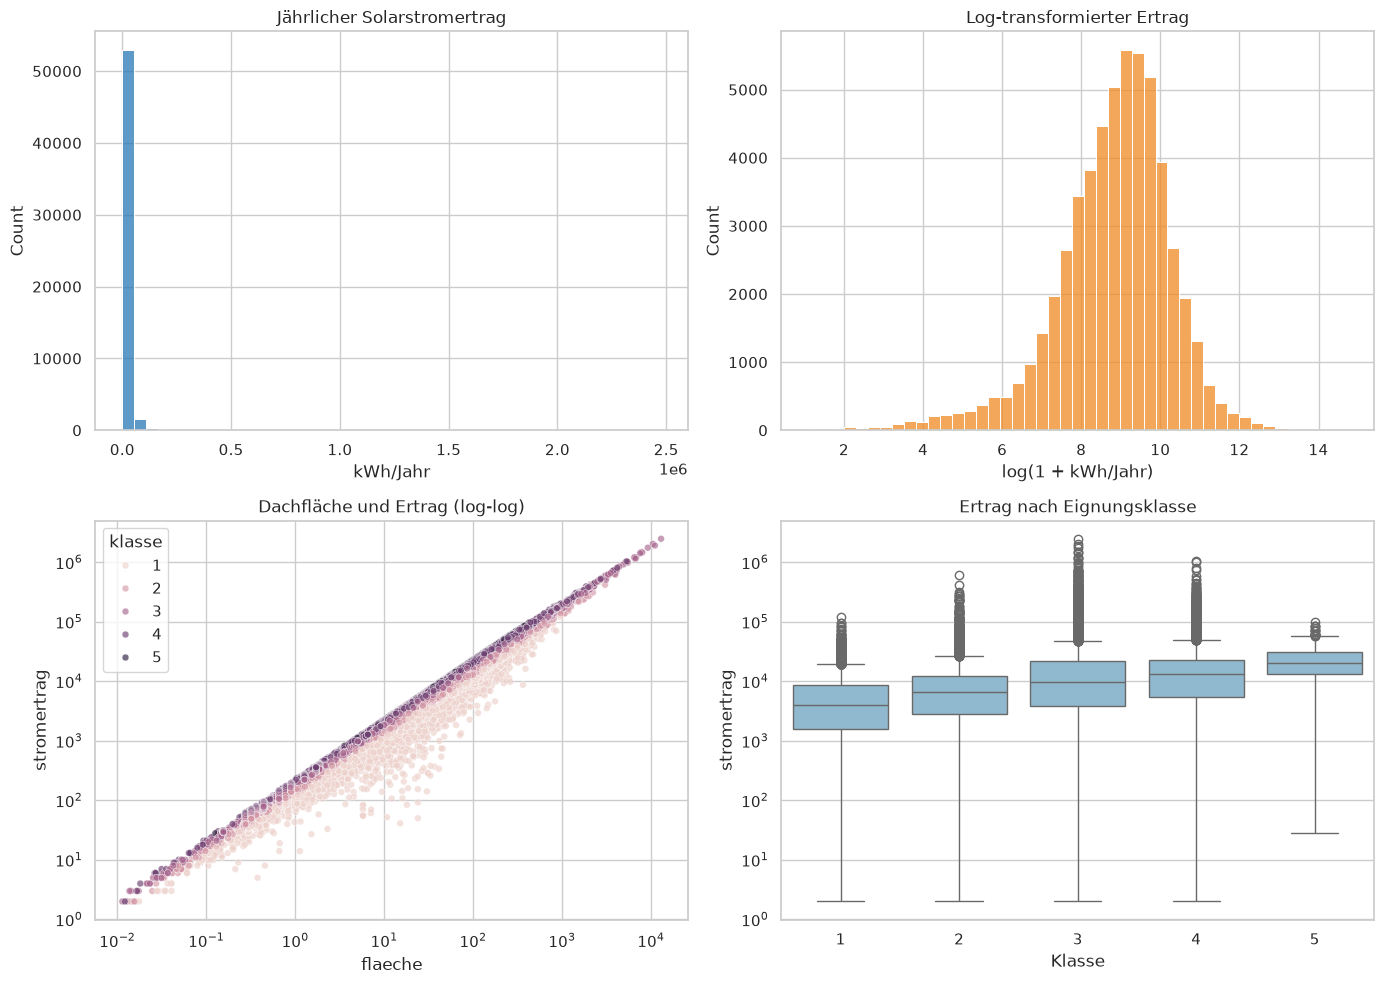

In [9]:
print("Dachflächen je Eignungsklasse:")
display(
    df.groupby("klasse", dropna=False)
    .agg(
        dachflaechen=("featureId", "count"),
        gebaeude=("building_id", "nunique"),
        median_flaeche_m2=("flaeche", "median"),
        median_ertrag_kwh_jahr=("stromertrag", "median"),
        mittelwert_ertrag_kwh_jahr=("stromertrag", "mean"),
    )
    .round(2)
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(df["stromertrag"], bins=45, ax=axes[0, 0], color="#2878B5")
axes[0, 0].set(title="Jährlicher Solarstromertrag", xlabel="kWh/Jahr")
sns.histplot(np.log1p(df["stromertrag"]), bins=45, ax=axes[0, 1], color="#F08A24")
axes[0, 1].set(title="Log-transformierter Ertrag", xlabel="log(1 + kWh/Jahr)")
sns.scatterplot(
    data=df,
    x="flaeche",
    y="stromertrag",
    hue="klasse",
    alpha=0.65,
    s=24,
    ax=axes[1, 0],
)
axes[1, 0].set(xscale="log", yscale="log", title="Dachfläche und Ertrag (log-log)")
sns.boxplot(data=df, x="klasse", y="stromertrag", ax=axes[1, 1], color="#86BBD8")
axes[1, 1].set(yscale="log", title="Ertrag nach Eignungsklasse", xlabel="Klasse")
fig.tight_layout()
plt.show()

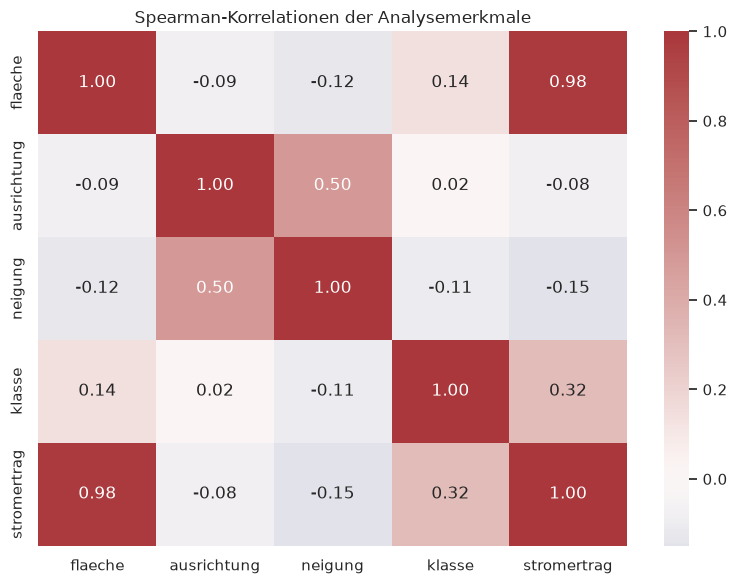

In [10]:
eda_features = ["flaeche", "ausrichtung", "neigung", "klasse", "stromertrag"]
corr_matrix = df[eda_features].corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Spearman-Korrelationen der Analysemerkmale")
plt.tight_layout()
plt.show()

## 5. Räumliche Visualisierung

Die API liefert Dachumrisse in LV95 (EPSG:2056). Für die interaktive
Folium-Karte werden die Koordinaten nach WGS84 (EPSG:4326) transformiert.
Die Kartenfarbe zeigt den geschätzten Ertrag pro Dachfläche, nicht eine
Messung real produzierten Stroms. Die Karte wird separat gespeichert und
verlinkt, damit sie nicht als grosse HTML-Ausgabe ins Notebook eingebettet wird.

[Interaktive Karte öffnen](sonnendach_winterthur_karte.html)


In [ ]:
def build_geojson_features(data: pd.DataFrame) -> list[dict]:
    """Erstellt Kartenfeatures aus bereinigten Zeilen mit GeoJSON-Geometrie."""
    features = []
    for row in data.itertuples(index=False):
        geometry = json.loads(row.geometry_geojson) if row.geometry_geojson else None
        if geometry is None:
            continue
        features.append(
            {
                "type": "Feature",
                "geometry": geometry,
                "properties": {
                    "featureId": int(row.featureId),
                    "building_id": (
                        int(row.building_id) if pd.notna(row.building_id) else "unbekannt"
                    ),
                    "klasse": int(row.klasse) if pd.notna(row.klasse) else "unbekannt",
                    "flaeche_m2": round(float(row.flaeche), 1),
                    "stromertrag_kwh_jahr": round(float(row.stromertrag), 1),
                },
            }
        )
    return features


geo_features = build_geojson_features(df)
if not geo_features:
    raise ValueError("Keine gültigen Geometrien für die Karte vorhanden.")
center_longitude, center_latitude = LV95_TO_WGS84.transform(
    city_area.centroid.x, city_area.centroid.y
)
map_center = [center_latitude, center_longitude]
city_area_wgs84 = transform_geometry(LV95_TO_WGS84.transform, city_area)
west, south, east, north = city_area_wgs84.bounds
yield_min = float(df["stromertrag"].min())
yield_max = float(df["stromertrag"].quantile(0.95))
yield_scale = folium.LinearColormap(
    colors=["#2c7bb6", "#abd9e9", "#ffffbf", "#fdae61", "#d7191c"],
    vmin=yield_min,
    vmax=yield_max,
    caption="BFE-Schätzwert Solarstromertrag (kWh/Jahr; Farbskala bis 95. Perzentil)",
)
roof_map = folium.Map(location=map_center, zoom_start=12, tiles="OpenStreetMap")
folium.GeoJson(
    {
        "type": "Feature",
        "properties": {"gemeinde": MUNICIPALITY},
        "geometry": mapping(city_area_wgs84),
    },
    name="Gemeindegrenze Winterthur",
    style_function=lambda feature: {
        "color": "#111827",
        "weight": 2,
        "fillOpacity": 0,
    },
).add_to(roof_map)
folium.GeoJson(
    {"type": "FeatureCollection", "features": geo_features},
    name="BFE-Dachflächen",
    style_function=lambda feature: {
        "fillColor": yield_scale(
            min(float(feature["properties"]["stromertrag_kwh_jahr"]), yield_max)
        ),
        "color": "#343a40",
        "weight": 0.4,
        "fillOpacity": 0.72,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "building_id",
            "klasse",
            "flaeche_m2",
            "stromertrag_kwh_jahr",
        ],
        aliases=["Gebäude-ID", "Eignungsklasse", "Fläche (m²)", "Ertrag (kWh/Jahr)"],
    ),
).add_to(roof_map)
yield_scale.add_to(roof_map)
folium.LayerControl().add_to(roof_map)
roof_map.fit_bounds([[south, west], [north, east]], padding=(12, 12))
roof_map.save(MAP_HTML)
print(f"Karte gespeichert unter {MAP_HTML}; dargestellte Dachflächen: {len(geo_features):,}")
display(FileLink(str(MAP_HTML.relative_to(CWD))))

## 6. Statistischer Zusammenhang mit p-Wert

Der Spearman-Test prüft einen monotonen Zusammenhang zwischen Dachfläche
und geschätztem Solarstromertrag. Der p-Wert quantifiziert die Evidenz gegen
die Nullhypothese eines Zusammenhangs von null. Bei großer Stichprobe sind
auch kleine Effekte oft statistisch signifikant; deshalb werden rho und
p-Wert gemeinsam berichtet. Eine Korrelation ist keine Kausalitätsaussage.

In [12]:
rho, p_value = spearmanr(df["flaeche"], df["stromertrag"])
print(f"Spearman rho (Dachfläche, Ertrag): {rho:.3f}")
print(f"p-Wert: {'< 0.001' if p_value < 0.001 else f'{p_value:.3g}'}")
if p_value < 0.05:
    print(
        "Interpretation: Der monotone Zusammenhang ist auf dem 5%-Niveau "
        "statistisch signifikant; die Stärke des Zusammenhangs ist rho."
    )
else:
    print("Interpretation: Auf dem 5%-Niveau ist kein statistisch signifikanter Zusammenhang belegt.")

Spearman rho (Dachfläche, Ertrag): 0.977
p-Wert: < 0.001
Interpretation: Der monotone Zusammenhang ist auf dem 5%-Niveau statistisch signifikant; die Stärke des Zusammenhangs ist rho.


## 7. Vorhersagemodelle und gebäudeweiser Test

Verglichen werden multiple lineare Regression und Random Forest Regression.
Der Zielwert wird intern mit `log1p` transformiert, um die starke
Rechtsschiefe abzumildern; Kennzahlen werden nach Rücktransformation in
kWh/Jahr auf der ursprünglichen Skala berechnet.

Als Prädiktoren dienen ausschließlich Fläche, Neigung und die zirkuläre
Kodierung der Ausrichtung. `gstrahlung`, Eignungsklasse, Finanz-/Ertrags-
Teilsummen und Gebäude-IDs werden ausgeschlossen, weil sie das Ergebnis
bereits enthalten, daraus abgeleitet sind oder keine verallgemeinerbaren
Dachmerkmale darstellen.

Der gruppierte 80/20-Split hält alle Dachflächen desselben Gebäudes in
genau einer Teilmenge. R² beschreibt erklärte Varianz, RMSE gewichtet große
Fehler stärker und MAE ist der mittlere absolute Fehler. Die Metriken sind
keine Aussage über reale Anlagenproduktion.

In [13]:
FEATURES = ["log_flaeche", "ausrichtung_sin", "ausrichtung_cos", "neigung"]
TARGET = "stromertrag"
X = df[FEATURES]
y = df[TARGET]
groups = df["building_group"]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = set(groups.iloc[train_idx])
test_groups = set(groups.iloc[test_idx])
assert train_groups.isdisjoint(test_groups), "Gebäude-Leakage im Train/Test-Split."
print(
    f"Training: {len(train_idx):,} Dächer / {len(train_groups):,} Gebäude; "
    f"Test: {len(test_idx):,} Dächer / {len(test_groups):,} Gebäude."
)
print(f"Gebäude-Überlappung: {len(train_groups & test_groups)}")

models = {
    "Multiple lineare Regression": TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), LinearRegression()),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
    "Random Forest": TransformedTargetRegressor(
        regressor=RandomForestRegressor(
            n_estimators=400,
            min_samples_leaf=3,
            random_state=SEED,
            n_jobs=-1,
        ),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
}

predictions: dict[str, np.ndarray] = {}
metric_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = np.maximum(model.predict(X_test), 0)
    predictions[name] = prediction
    metric_rows.append(
        {
            "Modell": name,
            "R²": r2_score(y_test, prediction),
            "RMSE_kWh_Jahr": np.sqrt(mean_squared_error(y_test, prediction)),
            "MAE_kWh_Jahr": mean_absolute_error(y_test, prediction),
        }
    )

baseline_prediction = np.full(len(y_test), y_train.median())
metric_rows.append(
    {
        "Modell": "Baseline (Trainingsmedian)",
        "R²": r2_score(y_test, baseline_prediction),
        "RMSE_kWh_Jahr": np.sqrt(mean_squared_error(y_test, baseline_prediction)),
        "MAE_kWh_Jahr": mean_absolute_error(y_test, baseline_prediction),
    }
)
metrics = pd.DataFrame(metric_rows).set_index("Modell").sort_values("RMSE_kWh_Jahr")
display(metrics.round(3))

Training: 44,222 Dächer / 16,664 Gebäude; Test: 11,055 Dächer / 4,167 Gebäude.
Gebäude-Überlappung: 0


,R²,RMSE_kWh_Jahr,MAE_kWh_Jahr
Modell,,,
Random Forest,0.992,2886.723,988.646
Multiple lineare Regression,0.821,13857.443,2282.296
Baseline (Trainingsmedian),-0.049,33556.554,12021.554


## 8. Ergebnisinterpretation und Modell-Diagnostik

Die Rangfolge wird anhand des Test-RMSE bestimmt. R² nahe 1 bedeutet, dass
das Modell einen großen Anteil der Teststreuung erklärt; R² nahe 0 ist
ungefähr nicht besser als eine Vorhersage des Testmittelwerts, negatives R²
ist schlechter. Ein niedrigerer RMSE/MAE ist besser. Die tatsächlichen
Zahlen unten werden bei jeder Notebook-Ausführung aus dem API-Datensatz neu
berechnet und sind nicht vorab festgeschrieben.

Bestes Modell nach Test-RMSE: Random Forest
Test-R² = 0.992, RMSE = 2886.7 kWh/Jahr, MAE = 988.6 kWh/Jahr.
Interpretation: Das beste Modell erklärt 99.2% der Streuung des BFE-Zielwerts im Gebäude-holdout-Test.
Das beste Modell senkt den RMSE gegenüber der Median-Baseline um 91.4% auf zuvor ungesehene Gebäude.
Die Ergebnisse gelten für die BFE-Potenzialschätzungen im gesamten Gemeindegebiet Winterthur. Sie zeigen keine kausale Wirkung und sind nicht ohne neue Validierung auf andere Regionen oder reale Anlagen übertragbar.


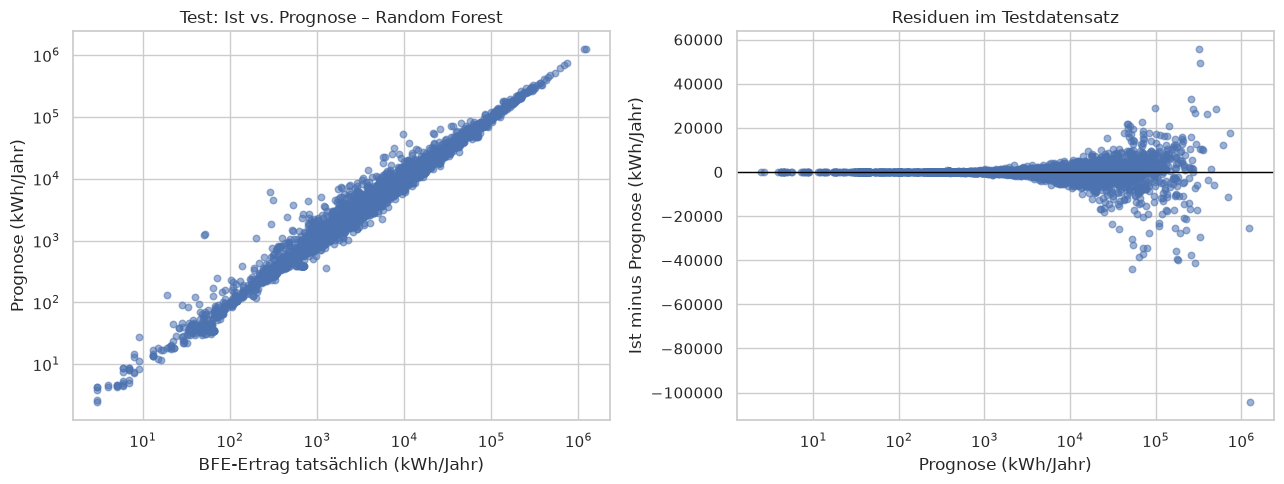

Random-Forest-Merkmalswichtigkeit (deskriptiv, keine Kausalwirkung):


,Wichtigkeit
log_flaeche,0.977
ausrichtung_cos,0.016
neigung,0.007
ausrichtung_sin,0.001


In [14]:
best_model_name = metrics.index[0]
best_metrics = metrics.loc[best_model_name]
baseline_metrics = metrics.loc["Baseline (Trainingsmedian)"]
print(f"Bestes Modell nach Test-RMSE: {best_model_name}")
print(
    f"Test-R² = {best_metrics['R²']:.3f}, "
    f"RMSE = {best_metrics['RMSE_kWh_Jahr']:.1f} kWh/Jahr, "
    f"MAE = {best_metrics['MAE_kWh_Jahr']:.1f} kWh/Jahr."
)
if best_metrics["R²"] >= 0:
    print(
        f"Interpretation: Das beste Modell erklärt {best_metrics['R²']:.1%} "
        "der Streuung des BFE-Zielwerts im Gebäude-holdout-Test."
    )
else:
    print(
        "Interpretation: Das beste Modell erklärt im Test weniger Varianz "
        "als eine konstante Vorhersage des Testmittelwerts (R² < 0)."
    )
if best_model_name != "Baseline (Trainingsmedian)" and (
    best_metrics["RMSE_kWh_Jahr"] < baseline_metrics["RMSE_kWh_Jahr"]
):
    relative_rmse_improvement = (
        1 - best_metrics["RMSE_kWh_Jahr"] / baseline_metrics["RMSE_kWh_Jahr"]
    ) * 100
    print(
        f"Das beste Modell senkt den RMSE gegenüber der Median-Baseline um "
        f"{relative_rmse_improvement:.1f}% auf zuvor ungesehene Gebäude."
    )
else:
    print(
        "Keines der Regressionsmodelle verbessert den Test-RMSE gegenüber "
        "der Median-Baseline. Die verfügbaren Dachmerkmale reichen für "
        "verlässliche Ertragsprognosen in diesem Gebiet nicht aus."
    )
print(
    "Die Ergebnisse gelten für die BFE-Potenzialschätzungen im gesamten "
    "Gemeindegebiet Winterthur. Sie zeigen keine kausale Wirkung und sind nicht "
    "ohne neue Validierung auf andere Regionen oder reale Anlagen übertragbar."
)

best_prediction = predictions.get(best_model_name)
if best_prediction is not None:
    residuals = y_test.to_numpy() - best_prediction
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].scatter(y_test, best_prediction, alpha=0.55, s=22)
    axes[0].set_xscale("log")
    axes[0].set_yscale("log")
    axes[0].set(
        title=f"Test: Ist vs. Prognose – {best_model_name}",
        xlabel="BFE-Ertrag tatsächlich (kWh/Jahr)",
        ylabel="Prognose (kWh/Jahr)",
    )
    axes[1].scatter(best_prediction, residuals, alpha=0.55, s=22)
    axes[1].axhline(0, color="black", linewidth=1)
    axes[1].set_xscale("log")
    axes[1].set(
        title="Residuen im Testdatensatz",
        xlabel="Prognose (kWh/Jahr)",
        ylabel="Ist minus Prognose (kWh/Jahr)",
    )
    fig.tight_layout()
    plt.show()

rf_model = models["Random Forest"].regressor_
rf_importance = pd.Series(
    rf_model.feature_importances_, index=FEATURES, name="Wichtigkeit"
).sort_values(ascending=False)
print("Random-Forest-Merkmalswichtigkeit (deskriptiv, keine Kausalwirkung):")
display(rf_importance.to_frame().round(3))

## 9. Fazit, Grenzen und Weitergabe

**Fazit:** Die Tabellen und Grafiken quantifizieren Verteilung,
Gebäudecluster, räumliches Muster, statistischen Flächen-Ertrags-
Zusammenhang und die Vorhersagegüte beider Regressionsmodelle. Die
Schlussfolgerungen sind aus den oben ausgegebenen, bei der Ausführung
berechneten Kennzahlen abzuleiten.

**Grenzen:** (1) Untersuchungsgebiet ist auf die Gemeinde Winterthur
beschränkt; (2) BFE-Potenzial ist eine Modellschätzung, kein real gemessener
Ertrag; (3) mehrere Dächer je Gebäude und bewusst gebäudeweiser Split;
(4) APIs und Modellversionen können sich ändern; (5) p-Werte belegen keine
Kausalität; (6) hohe Ausreißer bleiben erhalten und beeinflussen RMSE.

**Moodle-Abgabe:** Vor der Abgabe dieses Notebook von oben nach unten
ausführen und mit den Outputs speichern. Dazu `solar_winterthur_stadt_raw.csv`,
`solar_winterthur_stadt_clean.csv`, die SQLite-Datei und die HTML-Karte
hochladen. Persönliche Moodle-Anmeldung/Upload kann nicht automatisiert
werden. Quellen: geo.admin.ch REST API, Layer
`ch.bfe.solarenergie-eignung-daecher` und aktuelle
Winterthurer Gemeindegrenze; Abrufdatum beim Ausführen: aktuelles Datum.

**Video-Präsentation:** Die Bewertung verlangt eine Aufnahme mit
`Gruppengröße × 5 Minuten`. Vor der Aufnahme aktuelle Kennzahlen aus diesem
Notebook übernehmen. Vorschlag: Frage & Datensatz (15%), API und
Datenbereinigung (20%), EDA & Karte (20%), Methode und gebäudeweiser Split
(20%), Modellvergleich und Interpretation (20%), Grenzen/Fazit (5%).
Jedes Gruppenmitglied sollte einen Abschnitt frei erläutern; Notebook,
Folien und sichtbare Visualisierungen als Hilfsmittel verwenden.

**Kreative Vertiefung:** Das interaktive Dozenten-Quiz liegt in
`quiz_dozent.html` und kann offline im Browser geöffnet werden.